In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import root_mean_squared_error
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.data import load_fd001, add_rul, FEATURES
from src.validation import run_cv, oof_vorhersagen

In [2]:
train, test, rul = load_fd001()
train = add_rul(train, cap = 125)

In [3]:
X = train[FEATURES]
y = train["RUL"]
gfk = GroupKFold(n_splits = 10)
splits = list(gfk.split(X, y, groups = train["unit"]))
cv_lr = run_cv(LinearRegression(), X, y, splits)
cv_lr.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,21.485017,21.560367,9.509827,0.000667,0.523391,53.144905
std,0.149752,1.333467,3.260342,3.562756,0.067326,7.055259


In [4]:
cv_xgb = run_cv(XGBRegressor(random_state=42), X,y, splits)
cv_xgb.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,11.950677,19.225841,18.774737,-0.096558,0.424170,76.982822
std,0.188642,2.442047,13.600800,2.923220,0.043026,11.040047


In [5]:
neue_spalten = []

for col in FEATURES:
    for w in [5,25]:
        name = f"{col}_mean{w}"
        train[name] = train.groupby("unit")[col].transform(lambda s: s.rolling(w, min_periods = 1).mean())
        neue_spalten.append(name)

        name = f"{col}_std{w}"
        train[name] = train.groupby("unit")[col].transform(lambda s: s.rolling(w,min_periods=1).std())
        neue_spalten.append(name)

feature_cols = FEATURES + neue_spalten

In [6]:
len(feature_cols)

70

In [7]:
train["s2_mean5"].equals(train["s2_mean25"])

False

In [8]:
train[neue_spalten].isna().sum()

s2_mean5        0
s2_std5       100
s2_mean25       0
s2_std25      100
s3_mean5        0
s3_std5       100
s3_mean25       0
s3_std25      100
s4_mean5        0
s4_std5       100
s4_mean25       0
s4_std25      100
s8_mean5        0
s8_std5       100
s8_mean25       0
s8_std25      100
s11_mean5       0
s11_std5      100
s11_mean25      0
s11_std25     100
s13_mean5       0
s13_std5      100
s13_mean25      0
s13_std25     100
s15_mean5       0
s15_std5      100
s15_mean25      0
s15_std25     100
s17_mean5       0
s17_std5      100
s17_mean25      0
s17_std25     100
s7_mean5        0
s7_std5       100
s7_mean25       0
s7_std25      100
s12_mean5       0
s12_std5      100
s12_mean25      0
s12_std25     100
s20_mean5       0
s20_std5      100
s20_mean25      0
s20_std25     100
s21_mean5       0
s21_std5      100
s21_mean25      0
s21_std25     100
s9_mean5        0
s9_std5       100
s9_mean25       0
s9_std25      100
s14_mean5       0
s14_std5      100
s14_mean25      0
s14_std25 

In [9]:
std_spalten = []

for name in neue_spalten:
    if "_std" in name:
        std_spalten.append(name)
        

In [10]:
len(std_spalten)

28

In [11]:
train[std_spalten] = train[std_spalten].fillna(0)

In [12]:
train[feature_cols].isna().sum().sum()

np.int64(0)

In [13]:
X2 = train[feature_cols]

In [14]:
cv_roll_xgb = run_cv(XGBRegressor(random_state=42),X2,y,splits)
cv_roll_xgb.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,4.015343,17.187365,7.788014,-0.850030,0.436730,66.665333
std,0.049255,1.878350,2.727569,2.101363,0.041324,6.301363


In [15]:
cv_roll_lr = run_cv(LinearRegression(), X2, y, splits)
cv_roll_lr.drop(columns="fold").agg(["mean", "std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,17.841254,18.263552,6.039325,0.034131,0.507202,52.275315
std,0.083617,0.775009,1.180043,1.455382,0.039059,5.423435


In [16]:
(cv_roll_lr["rmse_val"]<cv_lr["rmse_val"]).sum()

np.int64(10)

In [17]:
(cv_roll_xgb["rmse_val"]<cv_xgb["rmse_val"]).sum()

np.int64(10)

## Ablation: Einzelzeilen vs. Rolling-Features

**Features:** Für jeden der 14 Sensoren aus `FEATURES` gleitender Mittelwert und gleitende Standardabweichung je Triebwerk (`groupby("unit")`), Fenster 5 (aktuelles Niveau) und 25 (Trend) → 56 neue Spalten, insgesamt 70 Features.
- **Nur Vergangenheit:** Das Fenster endet im aktuellen Zyklus, kein `center=True`.
- **Fenster ≤ 31:** Das kürzeste Test-Triebwerk hat 31 Zyklen, bewertet wird nur sein letzter Zyklus. So hat dort jedes Test-Triebwerk ein volles Fenster.
- **`min_periods=1`:** Alle Zeilen bleiben erhalten → identische `splits`, die Läufe sind Fold für Fold vergleichbar.
- **std im ersten Zyklus = 0:** Mit nur einem Wert im Fenster ist die Stichproben-Standardabweichung nicht definiert (n − 1 = 0) → 100 NaN, eins pro Triebwerk, mit 0 gefüllt (ein einzelner Wert hat keine Streuung). Nur die std-Spalten gefüllt, damit ein NaN in den Mean-Spalten als Fehler auffallen würde.

**Leakage:** Keins zwischen Triebwerken. Jedes Feature nutzt nur Werte desselben Triebwerks, und GroupKFold hält jedes Triebwerk komplett in Train oder Validierung. Prüffrage: Ändert sich ein Train-Feature, wenn man die Val-Triebwerke löscht? Nein.

**Hypothese vorab:** Beide Modelle verbessern sich, XGBoost stärker, weil die Glättung das Rauschen reduziert, das XGBoost auswendig lernt. LinReg bleibt durch die Linearität begrenzt.

**Ergebnis** (GroupKFold, 10 Folds, Mittelwert ± std über die Folds):

| Modell | Features | Train-RMSE | Val-RMSE | Lücke | NASA val | Max. Verspätung (Ø Fold-Maxima) |
|---|---|---|---|---|---|---|
| LinReg | Einzelzeilen | 21,49 | 21,56 ± 1,33 | 0,08 | 9,51 ± 3,26 | 53,1 |
| LinReg | Rolling | 17,84 | **18,26 ± 0,78** | 0,42 | **6,04 ± 1,18** | 52,3 |
| XGBoost | Einzelzeilen | 11,95 | 19,23 ± 2,44 | 7,28 | 18,77 ± 13,60 | 77,0 |
| XGBoost | Rolling | 4,02 | **17,19 ± 1,88** | 13,17 | **7,79 ± 2,73** | 66,7 |

**Befunde:**
1. **Beide Modelle werden besser, und zwar in allen 10 Folds.** Weil alle Läufe dieselben `splits` nutzen, lässt sich Fold für Fold vergleichen. Das ist aussagekräftiger als Mittelwert ± std, da die Fold-Streuung ähnlich groß ist wie die Verbesserung.
2. **Hypothese widerlegt: Nach RMSE profitiert LinReg stärker** (−3,3 Zyklen bzw. −15 % gegenüber −2,0 bzw. −11 %). Auch ihr Train-RMSE sinkt deutlich (21,5 → 17,8), die Features beheben also einen Teil des Underfittings. Vermutliche Erklärung (noch nicht geprüft): Die Rolling-Features sind nicht nur glatter, sie enthalten neue Information. Aus zwei Fenstermitteln (z. B. `s2_mean5 − s2_mean25`) kann LinReg linear ein Trendmaß bilden.
3. **XGBoost overfittet stärker:** Die Lücke wächst von 7,3 auf 13,2, der Train-RMSE liegt bei 4,0. Die Glättung senkt die Varianz also nicht, die 70 Features geben eher mehr Möglichkeiten zum Auswendiglernen. Die Validierung wird trotzdem besser → Regularisierung beim Tuning wird wichtiger.
4. **Beim NASA-Score gewinnt XGBoost relativ am meisten** (−59 % gegenüber −36 %), vor allem weil die großen Verspätungsfehler schrumpfen (77 → 67). Die Rangfolge hängt weiter von der Metrik ab (RMSE: XGBoost vorn, NASA: LinReg vorn), der Abstand beim NASA-Score sinkt aber von Faktor 2,0 auf 1,3.

In [18]:
diff_spalten = []

for col in FEATURES:
    name = f"{col}_diff5_25"
    train[name] = train[f"{col}_mean5"]-train[f"{col}_mean25"]
    diff_spalten.append(name)

feature_cols_b = feature_cols + diff_spalten

In [19]:
len(feature_cols_b)

84

In [20]:
X3 = train[feature_cols_b]
cv_roll_b_lr = run_cv(LinearRegression(),X3,y, splits)
cv_roll_b_lr.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,17.841254,18.263552,6.039325,0.034131,0.507202,52.275315
std,0.083617,0.775009,1.180043,1.455382,0.039059,5.423435


In [21]:
cv_roll_b_xgb = run_cv(XGBRegressor(random_state = 42),X3,y, splits)
cv_roll_b_xgb.drop(columns="fold").agg(["mean","std"])

,rmse_train,rmse_val,nasa_val,bias,anteil_spaet,max_spaet
mean,4.098777,15.965158,6.620394,-0.507108,0.444194,64.642193
std,0.077779,2.092405,2.704156,1.773379,0.044664,6.068696


In [22]:
(cv_roll_b_xgb["rmse_val"]<cv_roll_xgb["rmse_val"]).sum()

np.int64(10)

## Ablation 2: explizites Trend-Feature `mean5 − mean25`

**Feature:** Je Sensor die Differenz der beiden Fenstermittel (`s2_mean5 − s2_mean25` usw.) → 14 neue Spalten, insgesamt 84 Features. Kein `groupby` nötig, weil die Mean-Spalten schon je Triebwerk berechnet sind. Bei linearem Verlauf und vollem Fenster entspricht die Differenz der Steigung × 10 Zyklen (Abstand der Fenstermitten).

**Hypothese vorab:** XGBoost profitiert, LinReg bleibt exakt gleich. Ein Baum teilt immer nur an einem Feature und kann die Differenz zweier Features nur über viele Splits annähern. LinReg bildet Linearkombinationen und konnte diese Differenz schon vorher selbst bilden.

**Ergebnis** (GroupKFold, 10 Folds, Mittelwert ± std, Referenz = Rolling-Lauf):

| Modell | Features | Train-RMSE | Val-RMSE | Lücke | NASA val | Max. Verspätung (Ø Fold-Maxima) |
|---|---|---|---|---|---|---|
| LinReg | Rolling (70) | 17,84 | 18,26 ± 0,78 | 0,42 | 6,04 ± 1,18 | 52,3 |
| LinReg | + Differenz (84) | 17,84 | 18,26 ± 0,78 | 0,42 | 6,04 ± 1,18 | 52,3 |
| XGBoost | Rolling (70) | 4,02 | 17,19 ± 1,88 | 13,17 | 7,79 ± 2,73 | 66,7 |
| XGBoost | + Differenz (84) | 4,10 | **15,97 ± 2,09** | 11,87 | **6,62 ± 2,70** | 64,6 |

**Befunde:**
1. **Hypothese bestätigt.** LinReg ist in allen Werten identisch, weil die neuen Spalten exakte Linearkombinationen vorhandener Spalten sind (zugleich ein Kontrollcheck). XGBoost verbessert sich um 1,2 Zyklen (−7 %), der NASA-Score um 15 %. Fold-Vergleich: in 10 von 10 Folds besser.
2. **Die Overfitting-Lücke schrumpft leicht** (13,2 → 11,9). Mögliche Erklärung (nicht geprüft): Mit dem Trend als eigenem Feature braucht XGBoost weniger Splits, um ihn abzubilden.
3. **Gesamtbilanz XGBoost gegenüber Einzelzeilen:** Val-RMSE 19,23 → 15,97 (−17 %), NASA 18,77 → 6,62 (−65 %). Beim NASA-Score liegt LinReg nur noch knapp vorn (6,04 vs. 6,62).

In [23]:
oof_xgb = oof_vorhersagen(XGBRegressor(), X3, y, splits)
rmse_oof_xgb = root_mean_squared_error(oof_xgb,y)
rmse_oof_xgb

16.087109056707572

In [24]:
oof_lr = oof_vorhersagen(LinearRegression(), X3, y, splits)
rmse_oof_lr = root_mean_squared_error(oof_lr,y)
rmse_oof_lr

18.27845847128555

**Hypothese:**
Der Fehler ist bei hoher RUL (nahe 125) am größten und überwiegend negativ. Mit sinkender RUL wird er kleiner da die Sensoren dort einen Trend zeigen. 

In [25]:
fehler_plot = pd.DataFrame({
    "RUL" : y,
    "fehler_lr" : oof_lr-y,
    "fehler_xgb" : oof_xgb-y,
    "bin": (y//10)*10,
})

In [26]:
gruppen = fehler_plot.groupby("bin")

lr_mittel = gruppen["fehler_lr"].mean()
lr_std = gruppen["fehler_lr"].std()
anzahl = gruppen["RUL"].count()

xgb_mittel = gruppen["fehler_xgb"].mean()
xgb_std = gruppen["fehler_xgb"].std()
anzahl = gruppen["RUL"].count()

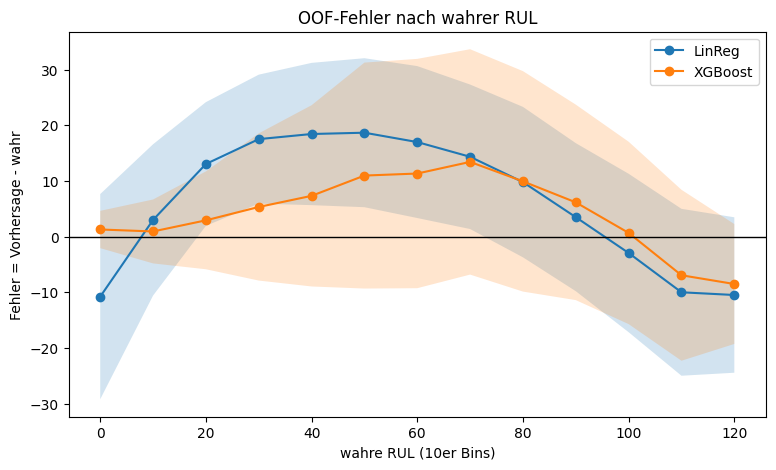

In [27]:
fig, ax = plt.subplots(figsize=(9,5))

x = lr_mittel.index

ax.plot(x, lr_mittel, marker="o", label = "LinReg")
ax.fill_between(x, lr_mittel - lr_std, lr_mittel + lr_std, alpha=0.2)
ax.plot(x, xgb_mittel, marker="o", label="XGBoost")
ax.fill_between(x, xgb_mittel - xgb_std, xgb_mittel+xgb_std, alpha = 0.2)


ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("wahre RUL (10er Bins)")
ax.set_ylabel("Fehler = Vorhersage - wahr")
ax.set_title("OOF-Fehler nach wahrer RUL")
ax.legend()
plt.show()

### Fehleranalyse (Out-of-Fold)

**Vorgehen:** Out-of-Fold-Vorhersagen mit denselben 10 GroupKFold-Splits (`oof_vorhersagen`): Jede Zeile wird von dem Modell vorhergesagt, das ihr Triebwerk nicht gesehen hat. Features: Rolling + Differenz (84). Fehler = Vorhersage − wahre RUL (positiv = zu spät), gruppiert in 10er-Bins der wahren RUL, Mittelwert ± std je Bin.

**Kontrolle:** OOF-RMSE über alle Zeilen: LinReg 18,27 / XGBoost 16,08 vs. CV-Mittel 18,26 / 15,97. Die Abweichung ist erwartet: `run_cv` mittelt die 10 Fold-RMSEs, OOF rechnet einen RMSE über alle Zeilen (die Wurzel ist nicht linear, die Folds sind unterschiedlich groß). Bei XGBoost ist der Abstand größer, weil seine Fold-RMSEs stärker streuen (std 2,09 vs. 0,78).

**Hypothese (vorher):** Der Fehler ist nahe RUL 125 am größten und überwiegend negativ (zu früh) und wird mit sinkender RUL kleiner, weil die Sensoren erst spät einen Trend zeigen.

**Befund:**

| wahre RUL | LinReg | XGBoost |
|---|---|---|
| 0 | ≈ −11 | ≈ +1 |
| größter mittlerer Fehler | ≈ +18,6 bei 50 | ≈ +13,4 bei 70 |
| 110–120 | ≈ −10 | ≈ −7 bis −9 |

- **Bestätigt:** Nahe 125 liegen beide Modelle zu früh. XGBoost ist nahe 0 fast fehlerfrei, mit schmalem Band.
- **Widerlegt:** Der größte mittlere Fehler liegt in der Mitte (LinReg ≈ 50, XGBoost ≈ 70) und ist **positiv, also zu spät**. Das ist die für die Wartung gefährliche Richtung, und hier entstehen die großen Verspätungsfehler, die den NASA-Score treiben (vgl. `03`).
- Bin 120 enthält über 8.000 Zeilen (≈ 40 %), weil alle gekappten Zeilen dort landen.

**Erklärung:** Das Label fällt ab 125 gleichmäßig um 1 pro Zyklus, die Sensoren bleiben aber lange flach und kippen erst spät. Bei wahrer RUL 50–70 sehen sie im Mittel noch eher aus wie im Plateau, deshalb schätzt das Modell zu hoch. Die Streuung zwischen den Triebwerken erklärt das breite Band, aber nicht die systematische Verschiebung des Mittelwerts.
- LinReg zeigt einen Bogen (zu früh → zu spät → zu früh): Ein lineares Modell kann die gekrümmte Beziehung zwischen Sensoren und RUL nicht abbilden. Bei RUL 0 sagt LinReg im Mittel negative Restlaufzeiten voraus (Extrapolation der steilen Sensorverläufe).
- XGBoost bleibt weitgehend im Bereich der Trainingslabels und hat dieses Problem kaum. Der Fehler in der Mitte ist flacher, aber ebenfalls positiv.

**Folgerung:**
- Kappungs-Sensitivität (115 / 125 / 135) prüfen, denn die Kappung bestimmt, wo das Plateau endet.
- Für die Wartungsentscheidung (`05_decision`) die Schwelle eher auf ein unteres Quantil legen statt auf die Punktschätzung.